# 02 · Cohort retention

**Question.** What share of new players come back after 1, 7 and 14 days, and does it differ by platform or country?
**Answer.** 37.0% come back on day 1, 6.7% on day 7 and 2.9% on day 14. iPhone players retain better than Android players on D1 and D7.
**Method.** A new player has a `firstOpen` event in the window. Retention on day N counts players active exactly N days after their first day, only for cohorts whose day N is observed and never on the 2025-03-27 data gap (`sql/02_retention.sql`). Intervals are 95% Wilson intervals.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from game_events import config, metrics
from game_events.data import connect_events
from game_events.queries import build_base_tables

con, readable, unreadable = connect_events()
build_base_tables(con)
print(f"{len(readable)} readable files, {len(unreadable)} skipped")

67 readable files, 1 skipped


## 1. New players

In [2]:
con.sql("""
    WITH f AS (SELECT user_id, COUNT(*) AS n FROM events WHERE event_name = 'firstOpen' GROUP BY 1),
         i AS (SELECT DISTINCT user_id FROM events WHERE event_name = '_identityCreate')
    SELECT (SELECT COUNT(DISTINCT user_id) FROM events)   AS players,
           (SELECT COUNT(*) FROM f)                        AS with_first_open,
           (SELECT MAX(n) FROM f)                          AS max_first_open_per_player,
           (SELECT COUNT(*) FROM i)                        AS with_identity_create,
           (SELECT COUNT(*) FROM f JOIN i USING (user_id)) AS in_both
""").show(max_width=200)

┌─────────┬─────────────────┬───────────────────────────┬──────────────────────┬─────────┐
│ players │ with_first_open │ max_first_open_per_player │ with_identity_create │ in_both │
│  int64  │      int64      │           int64           │        int64         │  int64  │
├─────────┼─────────────────┼───────────────────────────┼──────────────────────┼─────────┤
│   71679 │           48307 │                         2 │                50881 │   48303 │
└─────────┴─────────────────┴───────────────────────────┴──────────────────────┴─────────┘



`firstOpen` and `_identityCreate` agree on almost every player (48,303 of 48,307). `firstOpen` is used: it is the install event.

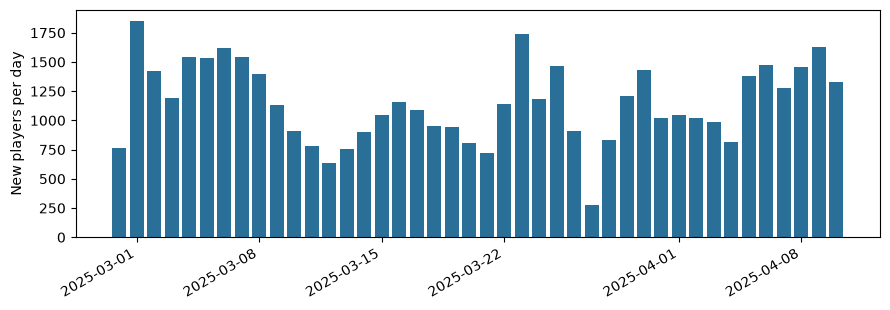

In [3]:
cohorts = con.execute("SELECT cohort_day, COUNT(*) AS new_players FROM new_players GROUP BY 1 ORDER BY 1").df()
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(cohorts["cohort_day"], cohorts["new_players"], color="#2a6f97")
ax.set_ylabel("New players per day")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

A smooth series with no spike on the first days: the cohort definition does not pick up players installed before the window.

## 2. Retention D1, D7, D14

In [4]:
overall = pd.concat([metrics.retention(con, n) for n in (1, 7, 14)], ignore_index=True)
overall

,day_n,segment,players,retained,pct,ci_low,ci_high
0,1,all,44447,16460,37.0,36.6,37.5
1,7,all,37161,2489,6.7,6.4,7.0
2,14,all,30373,893,2.9,2.8,3.1


## 3. Sensitivity: what counts as an active day?

Some events have no session id and look server-side (`achievementUpdated`, `currencyGranted`, `_propertiesUpdate`). If they can be recorded on a day when the player did not open the game, "any event" overstates retention. The stricter definition counts a day only if a session was opened (`_sessionStart`).

In [5]:
strict = pd.concat([metrics.retention(con, n, activity="session_start") for n in (1, 7, 14)], ignore_index=True)
comparison = overall[["day_n", "players", "pct"]].merge(
    strict[["day_n", "pct"]], on="day_n", suffixes=("_any_event", "_session_start"))
comparison["gap_points"] = (comparison["pct_any_event"] - comparison["pct_session_start"]).round(1)
comparison

,day_n,players,pct_any_event,pct_session_start,gap_points
0,1,44447,37.0,34.9,2.1
1,7,37161,6.7,6.5,0.2
2,14,30373,2.9,2.9,0.0


The gap is checked on day 1: are the players lost by the stricter definition server-side activity, or real play?

In [6]:
con.execute(f"""
    WITH cohort AS (
        SELECT user_id, cohort_day FROM new_players
        WHERE cohort_day + 1 <= DATE '{config.LAST_FULL_DAY}' AND cohort_day + 1 <> DATE '{config.GAP_DAY}'
    )
    SELECT COUNT(*)                                                            AS players,
           COUNT(a.user_id)                                                    AS active_d1_any_event,
           COUNT(*) FILTER (WHERE a.session_started)                           AS active_d1_session_start,
           COUNT(*) FILTER (WHERE a.user_id IS NOT NULL AND a.sessions = 0)    AS server_events_only,
           COUNT(*) FILTER (WHERE a.sessions > 0 AND NOT a.session_started)    AS played_without_new_session,
           COUNT(*) FILTER (WHERE a.sessions > 0 AND NOT a.session_started AND EXISTS (
               SELECT 1 FROM sessions s
               WHERE s.user_id = c.user_id
                 AND CAST(s.started_at AS DATE) = c.cohort_day
                 AND CAST(s.ended_at AS DATE) > c.cohort_day))                  AS session_from_day_0
    FROM cohort c
    LEFT JOIN active_days a ON a.user_id = c.user_id AND a.day = c.cohort_day + 1
""").df()

,players,active_d1_any_event,active_d1_session_start,server_events_only,played_without_new_session,session_from_day_0
0,44447,16460,15507,6,947,944


Requiring a `_sessionStart` loses 953 players on day 1. 944 of them were in a session that started on day 0 and continued past midnight, and only 6 were active through server-side events alone. "Any event" is kept: the stricter definition would miss real play, while server-side events add almost nothing.

## 4. By platform and country

Segments with fewer than 500 new players are left out: their rates are unstable.

In [7]:
metrics.retention_by(con, "platform")

,dimension,day_n,segment,players,retained,pct,ci_low,ci_high
0,platform,1,Android,31367,11167,35.6,35.1,36.1
1,platform,1,IPhonePlayer,13079,5293,40.5,39.6,41.3
2,platform,7,Android,26528,1692,6.4,6.1,6.7
3,platform,7,IPhonePlayer,10632,797,7.5,7.0,8.0
4,platform,14,Android,22367,637,2.8,2.6,3.1
5,platform,14,IPhonePlayer,8005,256,3.2,2.8,3.6


In [8]:
by_country = metrics.retention_by(con, "country", top=8)
by_country.sort_values(["day_n", "pct"], ascending=[True, False])

,dimension,day_n,segment,players,retained,pct,ci_low,ci_high
6,country,1,TH,3245,1376,42.4,40.7,44.1
1,country,1,ES,2024,819,40.5,38.3,42.6
4,country,1,IT,1805,711,39.4,37.2,41.7
0,country,1,DE,2744,1037,37.8,36.0,39.6
2,country,1,FR,2989,1130,37.8,36.1,39.6
3,country,1,GB,3964,1460,36.8,35.3,38.3
7,country,1,US,11499,4150,36.1,35.2,37.0
5,country,1,SA,2347,815,34.7,32.8,36.7
12,country,7,IT,1512,132,8.7,7.4,10.3
15,country,7,US,9605,722,7.5,7.0,8.1


## 5. Retention curve, day 1 to 14

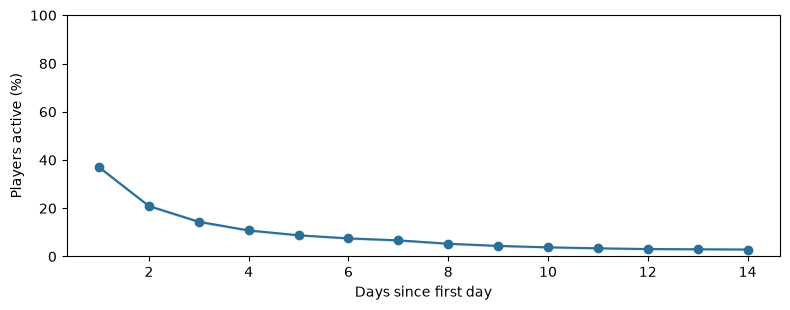

,day_n,players,pct
0,1,44447,37.0
1,2,42435,20.9
2,3,41439,14.4
3,4,39415,10.8
4,5,38634,8.8
5,6,38230,7.5
6,7,37161,6.7
7,8,36006,5.3
8,9,34946,4.4
9,10,33783,3.8


In [9]:
curve = metrics.retention_curve(con)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(curve["day_n"], curve["pct"], marker="o", color="#2a6f97")
ax.fill_between(curve["day_n"], curve["ci_low"], curve["ci_high"], alpha=0.2, color="#2a6f97")
ax.set_xlabel("Days since first day")
ax.set_ylabel("Players active (%)")
ax.set_ylim(0, 100)
plt.tight_layout()
plt.show()
curve[["day_n", "players", "pct"]]

Later days use fewer cohorts (they must be observed long enough), so the points do not describe exactly the same players.

## 6. Effect of the 2025-03-27 data gap

D1 by cohort day, gap included, to measure what excluding it changes.

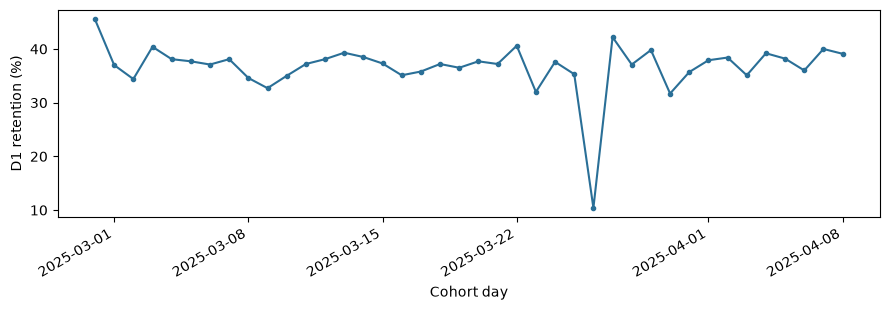

,cohort_day,players,d1_pct
24,2025-03-24,1185,37.6
25,2025-03-25,1463,35.3
26,2025-03-26,906,10.4
27,2025-03-27,277,42.2
28,2025-03-28,833,37.1
29,2025-03-29,1208,39.8


In [10]:
d1_by_cohort = con.execute(f"""
    SELECT p.cohort_day, COUNT(*) AS players, ROUND(100.0 * COUNT(a.user_id) / COUNT(*), 1) AS d1_pct
    FROM new_players p
    LEFT JOIN active_days a ON a.user_id = p.user_id AND a.day = p.cohort_day + 1
    WHERE p.cohort_day + 1 <= DATE '{config.LAST_FULL_DAY}'
    GROUP BY 1 ORDER BY 1
""").df()
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(d1_by_cohort["cohort_day"], d1_by_cohort["d1_pct"], marker=".", color="#2a6f97")
ax.set_ylabel("D1 retention (%)")
ax.set_xlabel("Cohort day")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()
d1_by_cohort[d1_by_cohort["cohort_day"].astype(str).between("2025-03-24", "2025-03-29")]

## 7. Funnel for new players

Same steps as notebook 01, on new players only, so that no progress made before the window is missed. The purchase step is also given for Android new players alone, the only platform where purchases are tracked.

In [11]:
metrics.funnel(con, population="new")

,step_order,event,players,android_players,pct_of_previous,pct_of_first,pct_of_first_android
0,1,gameOpened,48288,34005,NaN,100.0,100.0
1,2,tokenCashout,46918,32789,97.2,97.2,96.4
2,3,deviceUnlocked,46048,32039,98.1,95.4,94.2
3,4,zoneUnlocked,45650,31753,99.1,94.5,93.4
4,5,purchaseCompleted,720,720,1.6,1.5,2.1


## Findings

- **Cohorts.** 48,307 of the 71,679 players have a `firstOpen` event (one player has two: reinstall); the other 23,000 or so installed before 2025-02-28 and are not in the cohorts. Cohort sizes are smooth (about 600 to 1,850 new players per day); the first day (761) is partial.
- **Retention.** D1 is 37.0% (95% interval 36.6 to 37.5, 44,447 players), D7 is 6.7% (6.4 to 7.0, 37,161 players) and D14 is 2.9% (2.8 to 3.1, 30,373 players). The curve falls fast: 20.9% on day 2 and 14.4% on day 3, then flattens.
- **Definition of an active day.** Counting only days with a `_sessionStart` gives a D1 of 34.9% instead of 37.0% (D7 6.5% instead of 6.7%, D14 unchanged). The 953 players behind the D1 gap are almost all in a session started on day 0 and continued past midnight (944); 6 are active through server-side events only. Any event is the right definition here.
- **Platform.** iPhone players retain better than Android players on D1 (40.5% against 35.6%) and on D7 (7.5% against 6.4%): the intervals do not overlap. On D14 (3.2% against 2.8%) they overlap, so there is no clear difference. The reason is not known (players, device, version or ads may differ).
- **Country.** On D1 the eight largest countries range from 34.7% (SA) to 42.4% (TH), and the intervals of TH and SA do not overlap. Countries differ in platform mix, which was not controlled, and eight countries times three days makes many comparisons: treat country differences as leads, not findings.
- **The 2025-03-27 drop is a data gap, not players leaving.** The D1 of the 2025-03-26 cohort is 10.4% against 35 to 38% for its neighbours, and only 277 new players are seen on 2025-03-27 (against 600 to 1,850 on other days). Everyone seems affected, and the next cohorts return to 37 to 42%. This is consistent with missing events on that day; the cause (outage, tracking) remains unknown. For this reason every retention figure above leaves out the cohorts whose day N falls on 2025-03-27.
- **Funnel for new players.** 48,288 players opened the game; 97.2% reached `tokenCashout`, 98.1% of those `deviceUnlocked`, 99.1% of those `zoneUnlocked`, and 1.5% (720 players) `purchaseCompleted`. Almost no one is lost before the purchase, so these steps probably belong to a guided start and do not discriminate between players. `purchaseCompleted` is recorded for Android players only, so the purchase step is also measured on Android new players alone: 2.1% of them buy (720 of 34,005), against 1.5% when the iPhone players, who cannot have this event, are counted. The funnel in notebook 01 (all players) understated steps 3 and 4 for returning players, as expected.

**Limits.**
- "Active" means at least one event; section 3 shows that server-side events alone add 6 players at D1.
- Players without a `firstOpen` event are excluded from the cohorts, so the cohorts describe installs seen in the window only.
- The window is six weeks long: D14 only covers cohorts up to 2025-03-26.
- iPhone purchases are not visible in `purchaseCompleted`: no purchase rate can be given for iPhone players.